In [2]:
!pip install kagglehub[pandas-datasets]

In [3]:
import pandas as pd
import numpy as np
import sqlite3
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import kagglehub
from kagglehub import KaggleDatasetAdapter

In [4]:
file_path = "Wind Farm A/comma_event_info.csv"
events = kagglehub.load_dataset(
    KaggleDatasetAdapter.PANDAS,
    "azizkasimov/wind-turbine-scada-data-for-early-fault-detection",
    file_path,
)

file_path = "Wind Farm A/comma_feature_description.csv"
features = kagglehub.load_dataset(
    KaggleDatasetAdapter.PANDAS,
    "azizkasimov/wind-turbine-scada-data-for-early-fault-detection",
    file_path,
)

events.head()

/tmp/ipykernel_973/4114875831.py:2: DeprecationWarning: Use dataset_load() instead of load_dataset(). load_dataset() will be removed in a future version.
  events = kagglehub.load_dataset(


100%|██████████| 1.63k/1.63k [00:00<00:00, 2.48MB/s]
/tmp/ipykernel_973/4114875831.py:9: DeprecationWarning: Use dataset_load() instead of load_dataset(). load_dataset() will be removed in a future version.
  features = kagglehub.load_dataset(


100%|██████████| 3.97k/3.97k [00:00<00:00, 3.03MB/s]


,event_id,event_label,event_start,event_start_id,event_end,event_end_id,event_description
0,68,anomaly,2015-07-29 13:20:00,52063,2015-08-12 13:10:00,54076,Transformer failure
1,22,anomaly,2021-08-11 09:50:00,51888,2021-08-18 10:00:00,52892,Hydraulic group
2,72,anomaly,2021-10-09 08:40:00,52497,2021-10-16 08:40:00,53505,Gearbox failure
3,73,anomaly,2023-06-09 11:40:00,52745,2023-06-16 11:40:00,53753,Hydraulic group
4,0,anomaly,2022-08-05 06:10:00,52436,2022-08-19 06:10:00,54447,Generator bearing failure


In [5]:
features.head()

,sensor_name,statistics_type,description,unit,is_angle,is_counter
0,sensor_0,average,Ambient temperature,�C,False,False
1,sensor_1,average,Wind absolute direction,�,True,False
2,sensor_2,average,Wind relative direction,�,True,False
3,wind_speed_3,"maximum,minimum,average,std_dev",Windspeed,m/s,False,False
4,wind_speed_4,average,Estimated windspeed,m/s,False,False


In [6]:
cols_to_keep = [
    "id", "asset_id", "time_stamp", "train_test", "status_type_id",
    "wind_speed_3_avg", "sensor_0_avg", "sensor_1_avg",
    "sensor_11_avg", "sensor_43_avg", "sensor_50"
]

all_dfs = []
for eid in events["event_id"]:
    file_path = f"Wind Farm A/datasets/comma_{eid}.csv"
    temp = kagglehub.load_dataset(
        KaggleDatasetAdapter.PANDAS,
        "azizkasimov/wind-turbine-scada-data-for-early-fault-detection",
        file_path,
    )
    temp = temp[cols_to_keep].copy()
    temp["event_id"] = eid
    all_dfs.append(temp)

df = pd.concat(all_dfs, ignore_index=True)
df = df[[
    "id", "event_id", "asset_id", "time_stamp", "train_test", "status_type_id",
    "wind_speed_3_avg", "sensor_0_avg", "sensor_1_avg",
    "sensor_11_avg", "sensor_43_avg", "sensor_50"
]]
df.head()

/tmp/ipykernel_973/3233695733.py:10: DeprecationWarning: Use dataset_load() instead of load_dataset(). load_dataset() will be removed in a future version.
  temp = kagglehub.load_dataset(


100%|██████████| 33.9M/33.9M [00:03<00:00, 10.8MB/s]
/tmp/ipykernel_973/3233695733.py:10: DeprecationWarning: Use dataset_load() instead of load_dataset(). load_dataset() will be removed in a future version.
  temp = kagglehub.load_dataset(


100%|██████████| 33.1M/33.1M [00:03<00:00, 10.6MB/s]
/tmp/ipykernel_973/3233695733.py:10: DeprecationWarning: Use dataset_load() instead of load_dataset(). load_dataset() will be removed in a future version.
  temp = kagglehub.load_dataset(


100%|██████████| 33.8M/33.8M [00:03<00:00, 11.4MB/s]
/tmp/ipykernel_973/3233695733.py:10: DeprecationWarning: Use dataset_load() instead of load_dataset(). load_dataset() will be removed in a future version.
  temp = kagglehub.load_dataset(


100%|██████████| 33.9M/33.9M [00:03<00:00, 11.6MB/s]
/tmp/ipykernel_973/3233695733.py:10: DeprecationWarning: Use dataset_load() instead of load_dataset(). load_dataset() will be removed in a future version.
  temp = kagglehub.load_dataset(


100%|██████████| 34.4M/34.4M [00:03<00:00, 11.7MB/s]
/tmp/ipykernel_973/3233695733.py:10: DeprecationWarning: Use dataset_load() instead of load_dataset(). load_dataset() will be removed in a future version.
  temp = kagglehub.load_dataset(


... (14 outputs left out)

100%|██████████| 34.2M/34.2M [00:03<00:00, 11.6MB/s]
/tmp/ipykernel_973/3233695733.py:10: DeprecationWarning: Use dataset_load() instead of load_dataset(). load_dataset() will be removed in a future version.
  temp = kagglehub.load_dataset(


100%|██████████| 33.6M/33.6M [00:03<00:00, 11.5MB/s]
/tmp/ipykernel_973/3233695733.py:10: DeprecationWarning: Use dataset_load() instead of load_dataset(). load_dataset() will be removed in a future version.
  temp = kagglehub.load_dataset(


100%|██████████| 34.0M/34.0M [00:03<00:00, 11.2MB/s]


,id,event_id,asset_id,time_stamp,train_test,status_type_id,wind_speed_3_avg,sensor_0_avg,sensor_1_avg,sensor_11_avg,sensor_43_avg,sensor_50
0,0,68,11,2014-07-29 13:20:00,train,5,3.9,31.0,152.0,40.0,38.0,-1185.0
1,1,68,11,2014-07-29 13:30:00,train,5,6.0,31.0,86.1,40.0,38.0,-1050.0
2,2,68,11,2014-07-29 13:40:00,train,5,6.3,31.0,115.2,39.0,38.0,-1043.0
3,3,68,11,2014-07-29 13:50:00,train,0,6.0,32.0,129.3,43.0,37.0,40124.0
4,4,68,11,2014-07-29 14:00:00,train,0,7.1,32.0,137.7,49.0,36.0,99360.0


In [7]:
Path("data/raw").mkdir(parents=True, exist_ok=True)
Path("data/processed").mkdir(parents=True, exist_ok=True)

df.to_csv("data/raw/scada.csv", index=False)
events.to_csv("data/raw/events.csv", index=False)
features.to_csv("data/raw/features.csv", index=False)

In [8]:
df.shape

(1196747, 12)

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1196747 entries, 0 to 1196746
Data columns (total 12 columns):
 #   Column            Non-Null Count    Dtype  
---  ------            --------------    -----  
 0   id                1196747 non-null  int64  
 1   event_id          1196747 non-null  int64  
 2   asset_id          1196747 non-null  int64  
 3   time_stamp        1196747 non-null  object 
 4   train_test        1196747 non-null  object 
 5   status_type_id    1196747 non-null  int64  
 6   wind_speed_3_avg  1196747 non-null  float64
 7   sensor_0_avg      1196747 non-null  float64
 8   sensor_1_avg      1196747 non-null  float64
 9   sensor_11_avg     1196747 non-null  float64
 10  sensor_43_avg     1196747 non-null  float64
 11  sensor_50         1196747 non-null  float64
dtypes: float64(6), int64(4), object(2)
memory usage: 109.6+ MB


In [10]:
df.describe()

,id,event_id,asset_id,status_type_id,wind_speed_3_avg,sensor_0_avg,sensor_1_avg,sensor_11_avg,sensor_43_avg,sensor_50
count,1.196747e+06,1.196747e+06,1.196747e+06,1.196747e+06,1.196747e+06,1.196747e+06,1.196747e+06,1.196747e+06,1.196747e+06,1.196747e+06
mean,2.720275e+04,4.080538e+01,1.042951e+01,1.194069e+00,6.201962e+00,1.995072e+01,1.708527e+02,5.162426e+01,3.010808e+01,9.304541e+04
std,1.571098e+04,2.719184e+01,6.796280e+00,2.092604e+00,3.730365e+00,5.555743e+00,9.258916e+01,1.024465e+01,5.402276e+00,1.135679e+05
min,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,4.000000e-01,4.000000e+00,0.000000e+00,1.500000e+01,1.500000e+01,-5.367000e+03
25%,1.359900e+04,1.700000e+01,1.000000e+01,0.000000e+00,3.200000e+00,1.600000e+01,9.790000e+01,4.400000e+01,2.600000e+01,-5.610000e+02
50%,2.719800e+04,3.800000e+01,1.100000e+01,0.000000e+00,5.500000e+00,1.900000e+01,1.294000e+02,5.300000e+01,3.000000e+01,3.882700e+04
75%,4.079800e+04,6.900000e+01,1.300000e+01,0.000000e+00,8.500000e+00,2.400000e+01,2.601000e+02,6.000000e+01,3.400000e+01,1.611880e+05
max,5.615700e+04,9.200000e+01,2.100000e+01,5.000000e+00,2.660000e+01,4.100000e+01,3.590000e+02,7.200000e+01,5.100000e+01,3.712560e+05


In [11]:
df.isnull().sum()

,0
id,0
event_id,0
asset_id,0
time_stamp,0
train_test,0
status_type_id,0
wind_speed_3_avg,0
sensor_0_avg,0
sensor_1_avg,0
sensor_11_avg,0


In [12]:
events.isnull().sum()

,0
event_id,0
event_label,0
event_start,0
event_start_id,0
event_end,0
event_end_id,0
event_description,11


In [13]:
events["event_description"] = events["event_description"].fillna("Normal")
events.isnull().sum()

,0
event_id,0
event_label,0
event_start,0
event_start_id,0
event_end,0
event_end_id,0
event_description,0


In [14]:
df.duplicated().sum()

np.int64(0)

In [15]:
df = df.rename(columns={
    "wind_speed_3_avg": "wind_speed",
    "sensor_0_avg": "ambient_temp",
    "sensor_1_avg": "wind_direction",
    "sensor_11_avg": "gearbox_temp",
    "sensor_43_avg": "nacelle_temp",
    "sensor_50": "power_output"
})

df["time_stamp"] = pd.to_datetime(df["time_stamp"])
events["event_start"] = pd.to_datetime(events["event_start"])
events["event_end"] = pd.to_datetime(events["event_end"])

df.dtypes

,0
id,int64
event_id,int64
asset_id,int64
time_stamp,datetime64[ns]
train_test,object
status_type_id,int64
wind_speed,float64
ambient_temp,float64
wind_direction,float64
gearbox_temp,float64


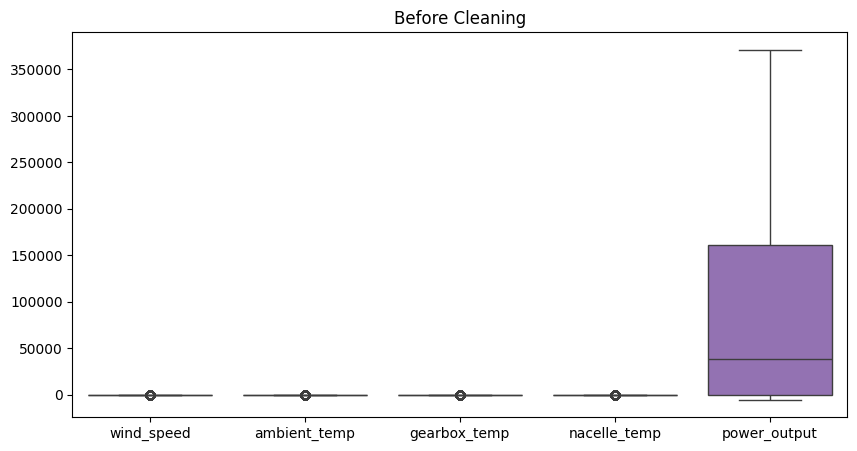

In [16]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=df[["wind_speed", "ambient_temp", "gearbox_temp", "nacelle_temp", "power_output"]])
plt.title("Before Cleaning")
plt.show()

In [17]:
Q1 = df["wind_speed"].quantile(0.25)
Q3 = df["wind_speed"].quantile(0.75)
IQR = Q3 - Q1
df["wind_speed"] = df["wind_speed"].clip(Q1 - 1.5 * IQR, Q3 + 1.5 * IQR)

Q1 = df["power_output"].quantile(0.25)
Q3 = df["power_output"].quantile(0.75)
IQR = Q3 - Q1
df["power_output"] = df["power_output"].clip(Q1 - 1.5 * IQR, Q3 + 1.5 * IQR)

df.describe()

,id,event_id,asset_id,time_stamp,status_type_id,wind_speed,ambient_temp,wind_direction,gearbox_temp,nacelle_temp,power_output
count,1.196747e+06,1.196747e+06,1.196747e+06,1196747,1.196747e+06,1.196747e+06,1.196747e+06,1.196747e+06,1.196747e+06,1.196747e+06,1.196747e+06
mean,2.720275e+04,4.080538e+01,1.042951e+01,2020-05-16 16:36:39.680968704,1.194069e+00,6.179320e+00,1.995072e+01,1.708527e+02,5.162426e+01,3.010808e+01,9.304541e+04
min,0.000000e+00,0.000000e+00,0.000000e+00,2013-10-10 08:40:00,0.000000e+00,4.000000e-01,4.000000e+00,0.000000e+00,1.500000e+01,1.500000e+01,-5.367000e+03
25%,1.359900e+04,1.700000e+01,1.000000e+01,2019-06-17 15:40:00,0.000000e+00,3.200000e+00,1.600000e+01,9.790000e+01,4.400000e+01,2.600000e+01,-5.610000e+02
50%,2.719800e+04,3.800000e+01,1.100000e+01,2021-04-13 08:40:00,0.000000e+00,5.500000e+00,1.900000e+01,1.294000e+02,5.300000e+01,3.000000e+01,3.882700e+04
75%,4.079800e+04,6.900000e+01,1.300000e+01,2022-08-18 15:10:00,0.000000e+00,8.500000e+00,2.400000e+01,2.601000e+02,6.000000e+01,3.400000e+01,1.611880e+05
max,5.615700e+04,9.200000e+01,2.100000e+01,2023-09-20 00:50:00,5.000000e+00,1.645000e+01,4.100000e+01,3.590000e+02,7.200000e+01,5.100000e+01,3.712560e+05
std,1.571098e+04,2.719184e+01,6.796280e+00,NaN,2.092604e+00,3.657499e+00,5.555743e+00,9.258916e+01,1.024465e+01,5.402276e+00,1.135679e+05


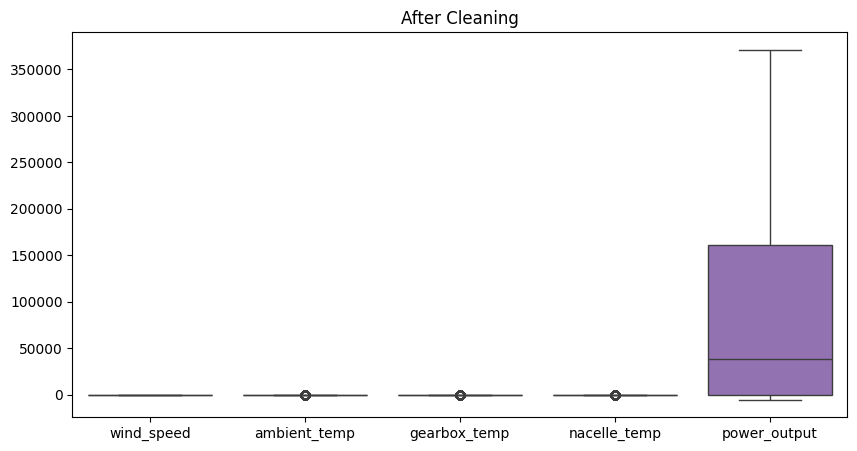

In [18]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=df[["wind_speed", "ambient_temp", "gearbox_temp", "nacelle_temp", "power_output"]])
plt.title("After Cleaning")
plt.show()

In [19]:

df["time_stamp"] = df["time_stamp"].dt.strftime("%Y-%m-%d %H:%M:%S")
df["time_stamp"] = df["time_stamp"].astype(str)
events["event_start"] = events["event_start"].astype(str)
events["event_end"] = events["event_end"].astype(str)

Path("data/processed").mkdir(parents=True, exist_ok=True)

df.to_csv("data/processed/scada_clean.csv", index=False)
events.to_csv("data/processed/events_clean.csv", index=False)
features.to_csv("data/processed/features_clean.csv", index=False)

In [20]:
dic = pd.DataFrame({
    "Column": df.columns,
    "Data_Type": df.dtypes.astype(str).values,
    "Description": [
        "Row ID",
        "Event ID",
        "Asset ID",
        "Timestamp",
        "Train or Prediction",
        "Turbine Status ID",
        "Wind Speed",
        "Ambient Temperature",
        "Wind Direction",
        "Gearbox Temperature",
        "Nacelle Temperature",
        "Power Output"
    ]
})
dic.to_csv("data/processed/dic.csv", index=False)
dic

,Column,Data_Type,Description
0,id,int64,Row ID
1,event_id,int64,Event ID
2,asset_id,int64,Asset ID
3,time_stamp,object,Timestamp
4,train_test,object,Train or Prediction
5,status_type_id,int64,Turbine Status ID
6,wind_speed,float64,Wind Speed
7,ambient_temp,float64,Ambient Temperature
8,wind_direction,float64,Wind Direction
9,gearbox_temp,float64,Gearbox Temperature


In [33]:
# stat from here (me) till the end
df.describe()

,id,event_id,asset_id,status_type_id,wind_speed,ambient_temp,wind_direction,gearbox_temp,nacelle_temp,power_output
count,1.196747e+06,1.196747e+06,1.196747e+06,1.196747e+06,1.196747e+06,1.196747e+06,1.196747e+06,1.196747e+06,1.196747e+06,1.196747e+06
mean,2.720275e+04,4.080538e+01,1.042951e+01,1.194069e+00,6.179320e+00,1.995072e+01,1.708527e+02,5.162426e+01,3.010808e+01,9.304541e+04
std,1.571098e+04,2.719184e+01,6.796280e+00,2.092604e+00,3.657499e+00,5.555743e+00,9.258916e+01,1.024465e+01,5.402276e+00,1.135679e+05
min,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,4.000000e-01,4.000000e+00,0.000000e+00,1.500000e+01,1.500000e+01,-5.367000e+03
25%,1.359900e+04,1.700000e+01,1.000000e+01,0.000000e+00,3.200000e+00,1.600000e+01,9.790000e+01,4.400000e+01,2.600000e+01,-5.610000e+02
50%,2.719800e+04,3.800000e+01,1.100000e+01,0.000000e+00,5.500000e+00,1.900000e+01,1.294000e+02,5.300000e+01,3.000000e+01,3.882700e+04
75%,4.079800e+04,6.900000e+01,1.300000e+01,0.000000e+00,8.500000e+00,2.400000e+01,2.601000e+02,6.000000e+01,3.400000e+01,1.611880e+05
max,5.615700e+04,9.200000e+01,2.100000e+01,5.000000e+00,1.645000e+01,4.100000e+01,3.590000e+02,7.200000e+01,5.100000e+01,3.712560e+05


In [21]:

numerical_cols = [
    'wind_speed',
    'ambient_temp',
    'wind_direction',
    'gearbox_temp',
    'nacelle_temp',
    'power_output'
]
df[numerical_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
wind_speed,1196747.0,6.179320,3.657499,0.4,3.2,5.5,8.5,16.45
ambient_temp,1196747.0,19.950724,5.555743,4.0,16.0,19.0,24.0,41.00
wind_direction,1196747.0,170.852698,92.589162,0.0,97.9,129.4,260.1,359.00
gearbox_temp,1196747.0,51.624264,10.244653,15.0,44.0,53.0,60.0,72.00
nacelle_temp,1196747.0,30.108077,5.402276,15.0,26.0,30.0,34.0,51.00
power_output,1196747.0,93045.407991,113567.948808,-5367.0,-561.0,38827.0,161188.0,371256.00


In [22]:

df[numerical_cols].var()

df[numerical_cols].skew()

df[numerical_cols].median()

,0
wind_speed,5.5
ambient_temp,19.0
wind_direction,129.4
gearbox_temp,53.0
nacelle_temp,30.0
power_output,38827.0


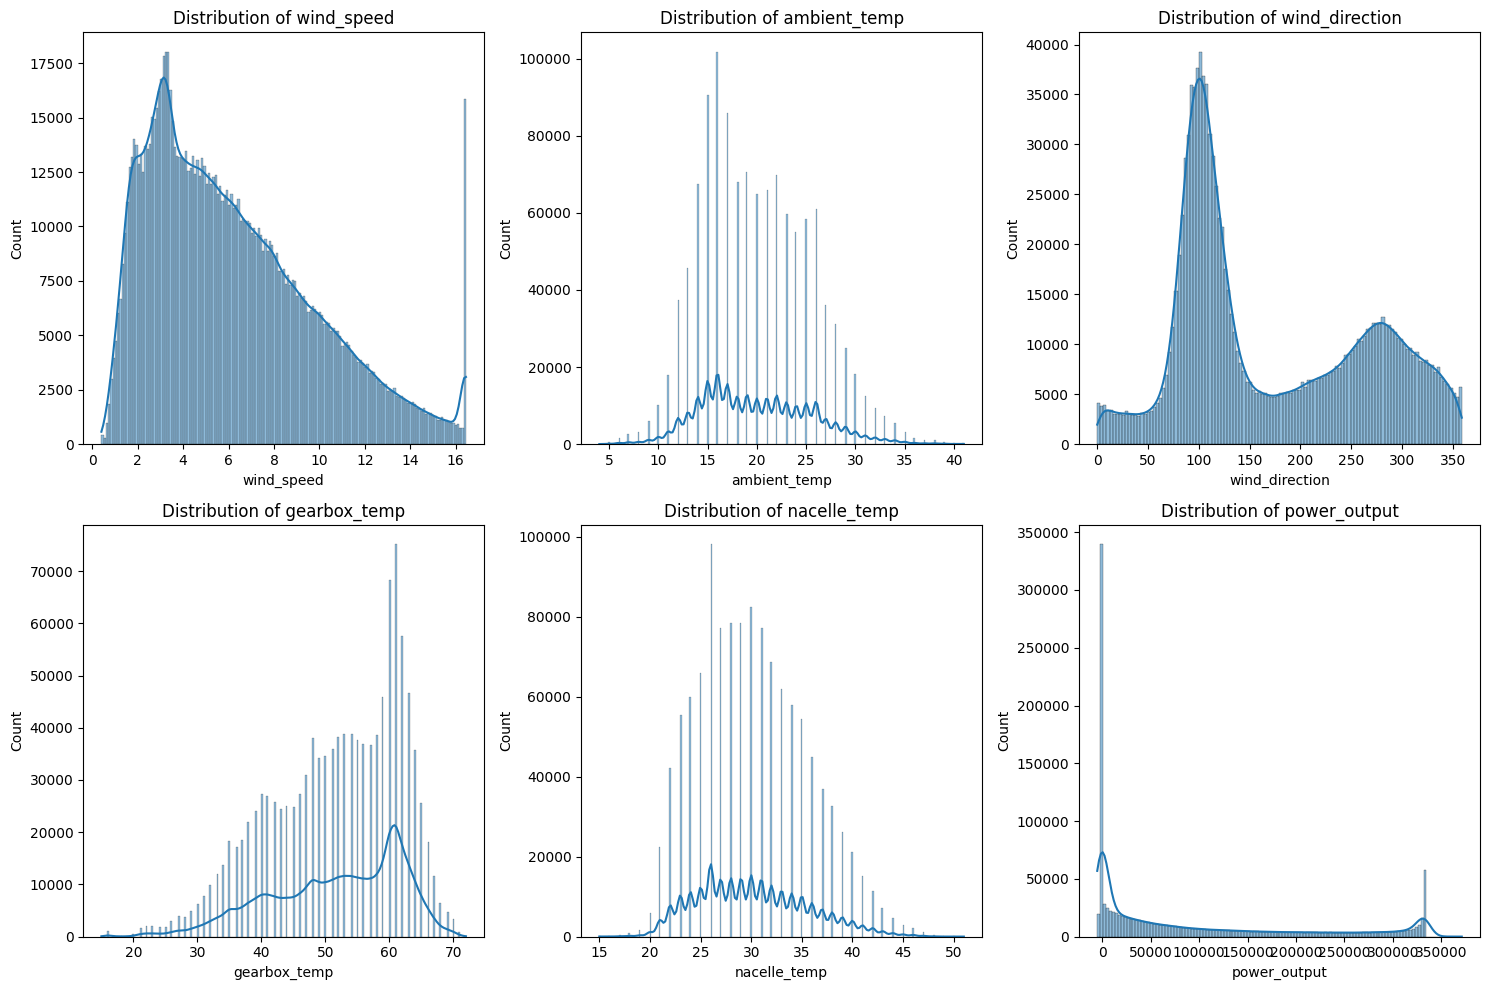

In [23]:
# 2- el Distributions [Histograms]
# part 1
plt.figure(figsize=(15, 10))

for i, col in enumerate(numerical_cols, 1):
    plt.subplot(2, 3, i)
    sns.histplot(data=df, x=col, kde=True)
    plt.title(f'Distribution of {col}')

plt.tight_layout()
plt.show()

In [1]:
plt.figure(figsize=(15, 10))

for i, col in enumerate(numerical_cols, 1):
    plt.subplot(2, 3, i)
    sns.boxplot(y=df[col])
    plt.title(f'Boxplot of {col}')

plt.tight_layout()
plt.show()

NameError: name 'plt' is not defined

In [24]:


correlation_matrix = df[numerical_cols].corr()
correlation_matrix

,wind_speed,ambient_temp,wind_direction,gearbox_temp,nacelle_temp,power_output
wind_speed,1.000000,0.181188,-0.328214,0.788205,0.489167,0.910198
ambient_temp,0.181188,1.000000,-0.102394,0.303361,0.869805,0.115722
wind_direction,-0.328214,-0.102394,1.000000,-0.252178,-0.210632,-0.331274
gearbox_temp,0.788205,0.303361,-0.252178,1.000000,0.524921,0.771333
nacelle_temp,0.489167,0.869805,-0.210632,0.524921,1.000000,0.441890
power_output,0.910198,0.115722,-0.331274,0.771333,0.441890,1.000000


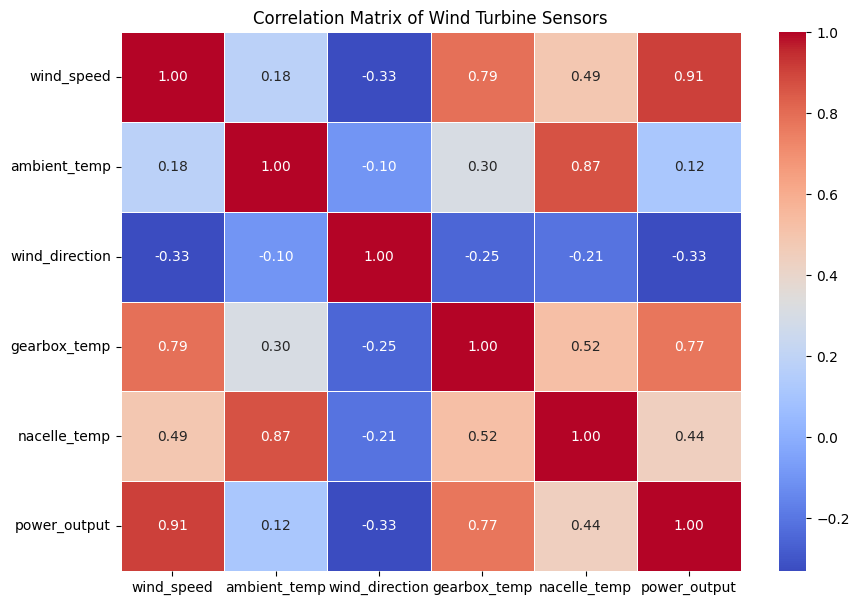

In [25]:

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)
plt.title('Correlation Matrix of Wind Turbine Sensors')
plt.show()

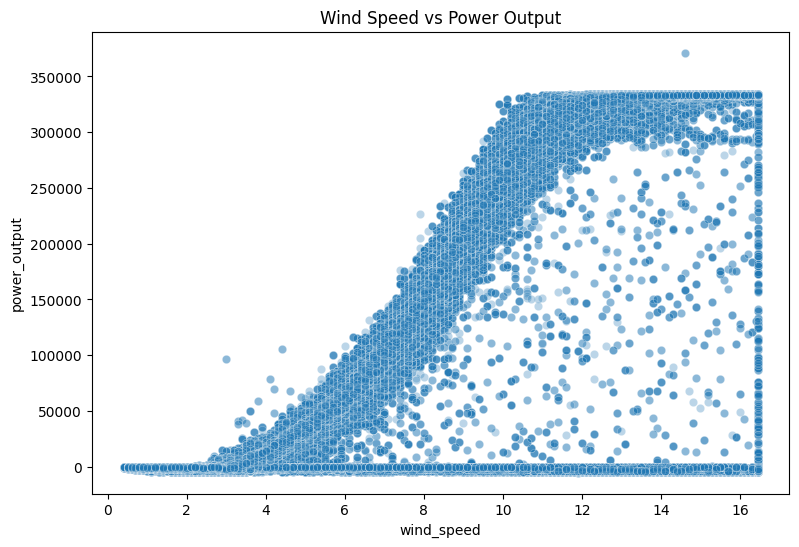

In [26]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x='wind_speed',
    y='power_output',
    alpha=0.3
)
plt.title('Wind Speed vs Power Output')
plt.show()

In [27]:
asset_analysis = df.groupby('asset_id').agg(
    avg_wind_speed=('wind_speed', 'mean'),
    avg_power=('power_output', 'mean'),
    max_power=('power_output', 'max'),
    avg_gearbox_temp=('gearbox_temp', 'mean'),
    total_readings=('id', 'count')
).round(2)
asset_analysis.sort_values(
    by='avg_power',
    ascending=False
)

,avg_wind_speed,avg_power,max_power,avg_gearbox_temp,total_readings
asset_id,,,,,
0,6.40,96742.05,334355.0,51.39,272477
21,6.19,96444.58,334398.0,51.46,215564
13,6.09,95247.27,334277.0,55.00,216543
11,6.16,90643.15,371256.0,50.85,217950
10,6.04,86870.59,334458.0,49.93,274213


In [28]:
status_analysis = df.groupby('status_type_id').agg(
    avg_power=('power_output', 'mean'),
    avg_wind_speed=('wind_speed', 'mean'),
    avg_gearbox_temp=('gearbox_temp', 'mean'),
    total_readings=('id', 'count')
).round(2)
status_analysis

,avg_power,avg_wind_speed,avg_gearbox_temp,total_readings
status_type_id,,,,
0,117666.72,6.90,54.42,898672
3,90494.13,7.50,48.84,23689
4,69756.44,5.39,52.75,13999
5,9554.20,3.62,42.19,260387


In [29]:
df_analysis = df.merge(
    events[['event_id', 'event_label', 'event_description']],
    on='event_id',
    how='left'
)
event_analysis = df_analysis.groupby('event_description').agg(
    avg_power=('power_output', 'mean'),
    avg_gearbox_temp=('gearbox_temp', 'mean'),
    avg_nacelle_temp=('nacelle_temp', 'mean'),
    total_readings=('id', 'count')
).round(2)
event_analysis

,avg_power,avg_gearbox_temp,avg_nacelle_temp,total_readings
event_description,,,,
Gearbox failure,92152.75,50.93,30.86,107674
Generator bearing failure,88377.42,50.19,30.36,111144
Hydraulic group,95712.94,52.44,29.98,322177
Normal,92657.07,51.63,29.97,601394
Transformer failure,92844.14,51.04,30.37,54358


In [30]:
df['wind_band'] = pd.cut(
    df['wind_speed'],
    bins=[-float('inf'), 4, 10, float('inf')],
    labels=['Low Wind', 'Medium Wind', 'High Wind']
)
wind_analysis = df.groupby('wind_band', observed=True).agg(
    avg_power=('power_output', 'mean'),
    avg_gearbox_temp=('gearbox_temp', 'mean'),
    total_readings=('id', 'count')
).round(2)
wind_analysis

,avg_power,avg_gearbox_temp,total_readings
wind_band,,,
Low Wind,497.35,41.05,420116
Medium Wind,94085.57,55.70,585155
High Wind,292925.62,62.37,191476
